# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
# !pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

In [2]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/tmp/ipykernel_2834284/1236436484.py:8: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, facecolor="white")


GPU available: False
scanpy 1.12.5 | squidpy 1.8.4


/tmp/ipykernel_2834284/1236436484.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [3]:
# Cluster compute nodes cannot reach the Census S3 bucket, so the provided query
# (cell 1.1, 10 whole donors x 2000 cells, seed 0) was run on a laptop and saved.
rng = np.random.default_rng(0)   # the starter defines this in the Census cell; later cells (silhouette subsample) use it
adata = sc.read_h5ad("census_sample.h5ad")
donors = adata.obs["donor_id"].unique()
print(f"loaded sample: {adata.n_obs:,} cells, {len(donors)} donors")
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

loaded sample: 20,000 cells, 10 donors

20,000 cells from 10 donors
cell_type_broad
T                   12121
Other                3125
Endothelial          1466
Macrophage           1260
Fibroblast           1118
B                     586
Epithelial/Tumor      152
Monocyte               73
NK                     61
DC                     38
Name: count, dtype: int64


/tmp/ipykernel_2834284/649836978.py:8: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [4]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="donor_id",
                            span=0.4)  # span 0.3 (default) fails the loess fit on 2 donors; 0.4 fixes it
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/scratch/bhatia.dh/conda/envs/biot8/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [5]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

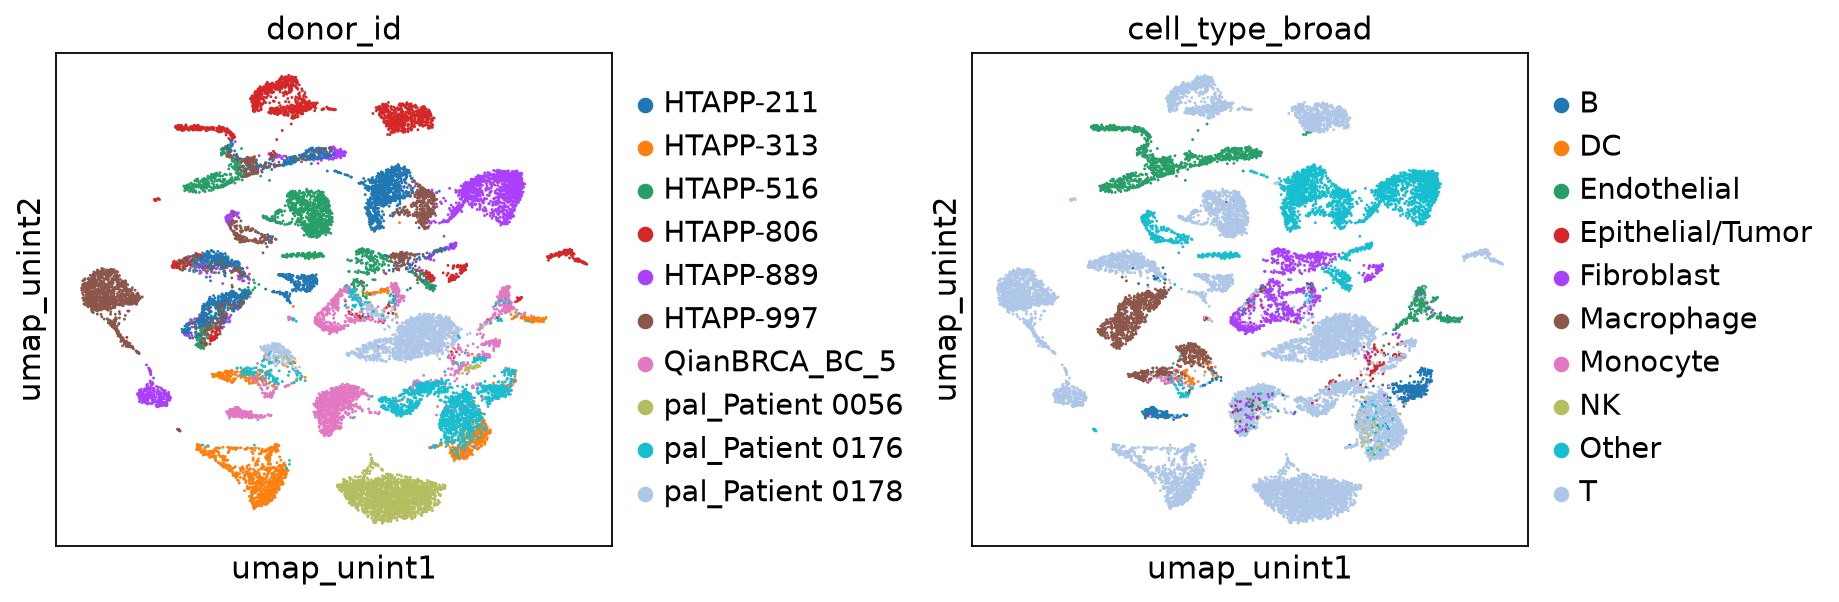

In [6]:
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5)

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

The map is organised by donor more than by biology. Cells of the same type are split into separate islands, and many islands come from a single donor (for example the T cells sit in many different islands).

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [7]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

/scratch/bhatia.dh/conda/envs/biot8/lib/python3.12/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python3.12 /scratch/bhatia.dh/conda/envs/biot8/lib/python3. ...
GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/scratch/bhatia.dh/conda/envs/biot8/lib/python3.12/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python3.12 /scratch/bhatia.dh/conda/envs/biot8/lib/python3. ...
/scratch/bhatia.dh/conda/envs/biot8/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/scratch/bhatia.dh/conda/envs/biot8/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Training:   0%|          | 0/60 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.


scVI done


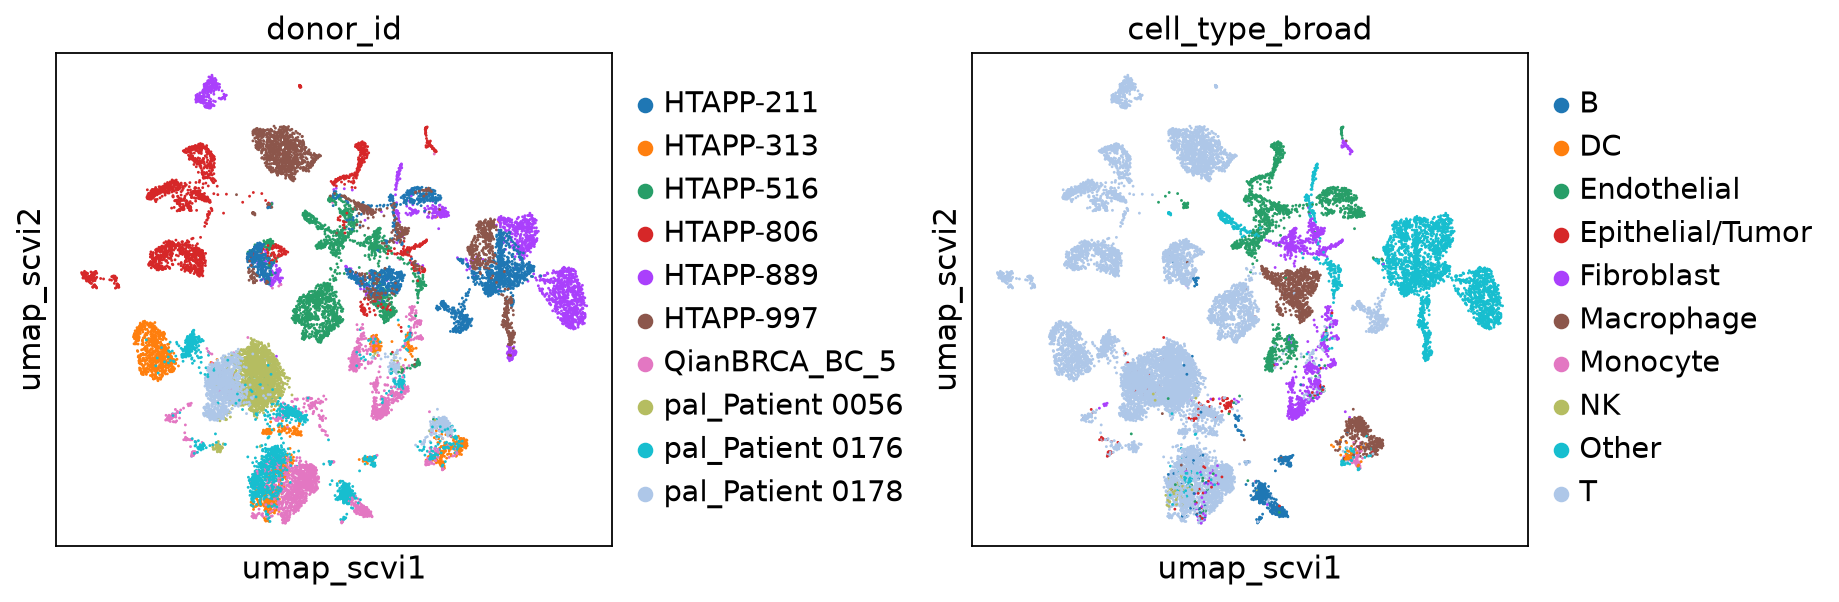

In [8]:
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5)

## 1.5 · Harmony, a fair baseline  *(provided)*

In [9]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-19 16:28:20,732 - harmonypy - INFO - Running Harmony


2026-11-19 16:28:20,734 - harmonypy - INFO -   Parameters:


2026-11-19 16:28:20,734 - harmonypy - INFO -     max_iter_harmony: 10


2026-11-19 16:28:20,735 - harmonypy - INFO -     max_iter_kmeans: 4


2026-11-19 16:28:20,736 - harmonypy - INFO -     epsilon_cluster: 0.001


2026-11-19 16:28:20,736 - harmonypy - INFO -     epsilon_harmony: 0.01


... (19 outputs left out)

2026-11-19 16:28:21,071 - harmonypy - INFO - Iteration 9 of 10


2026-11-19 16:28:21,098 - harmonypy - INFO - Iteration 10 of 10


2026-11-19 16:28:21,126 - harmonypy - INFO - Stopped before convergence


Harmony done


## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

In [10]:
from sklearn.metrics import silhouette_score
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
rows = []
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    rows.append((name, round(batch,3), round(bio,3)))
print(pd.DataFrame(rows, columns=["method","donor silhouette (lower = better mixing)","cell-type silhouette (higher = better)"]).to_string(index=False))

        method  donor silhouette (lower = better mixing)  cell-type silhouette (higher = better)
No integration                                     0.091                                  -0.010
       Harmony                                    -0.082                                   0.026
          scVI                                    -0.029                                   0.012


**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

I would use Harmony. It has the lowest donor silhouette (-0.082, against -0.029 for scVI and 0.091 with no integration) and the highest cell-type silhouette (0.026, against 0.012 and -0.010). All the cell-type scores are near zero, so the differences in keeping biology are small and the scores are rough. scVI did not clearly beat the simple method. My scVI ran on a CPU for 60 epochs, so it may be under-trained.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

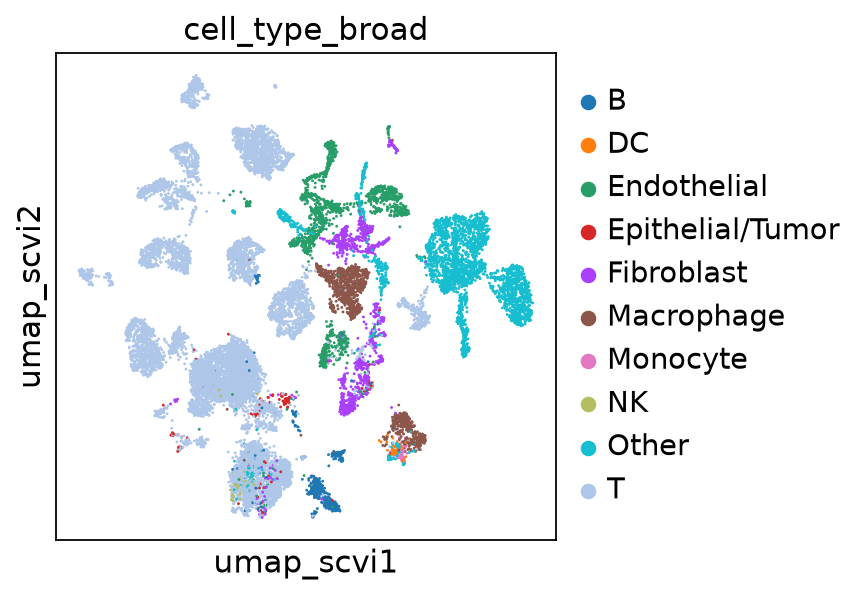

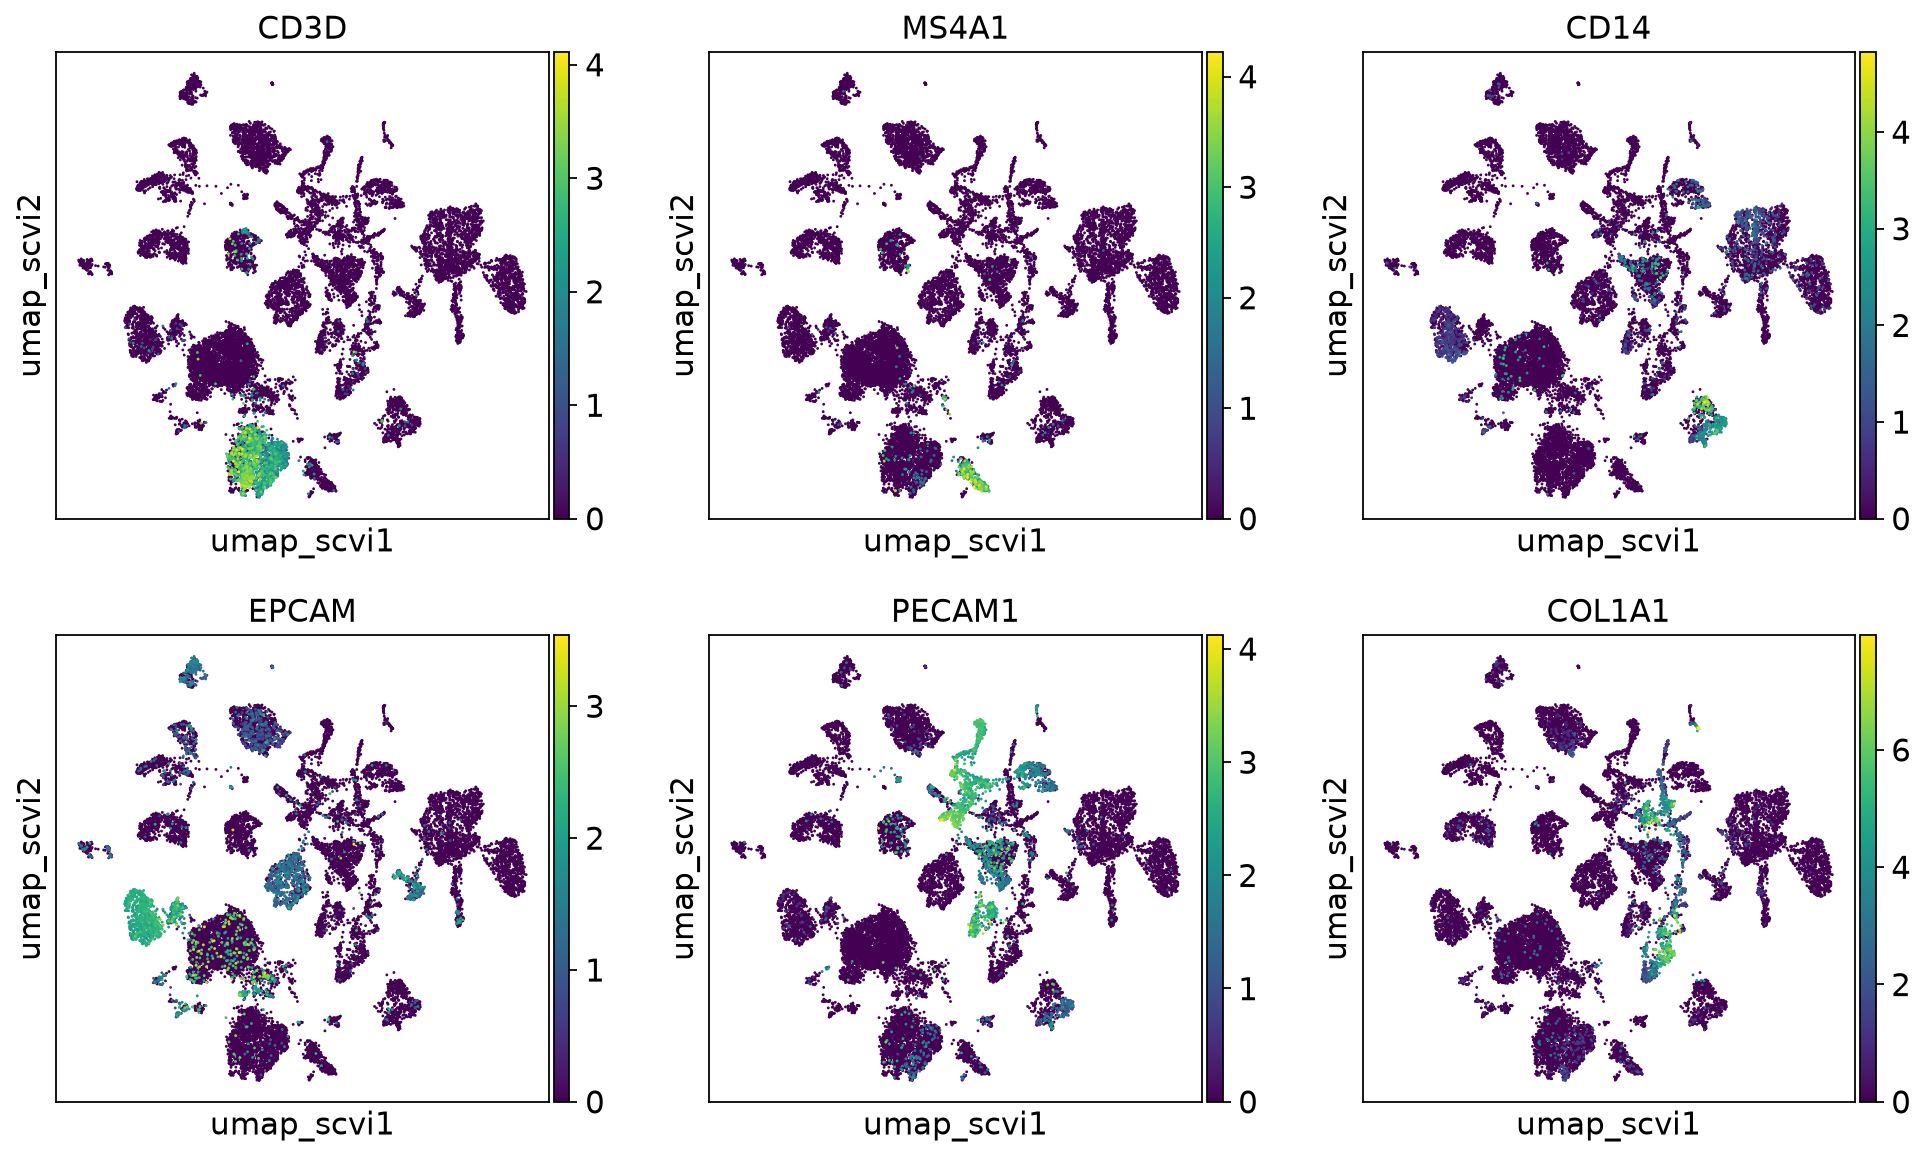

In [11]:
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad")
markers = [g for g in ["CD3D","MS4A1","CD14","EPCAM","PECAM1","COL1A1"] if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

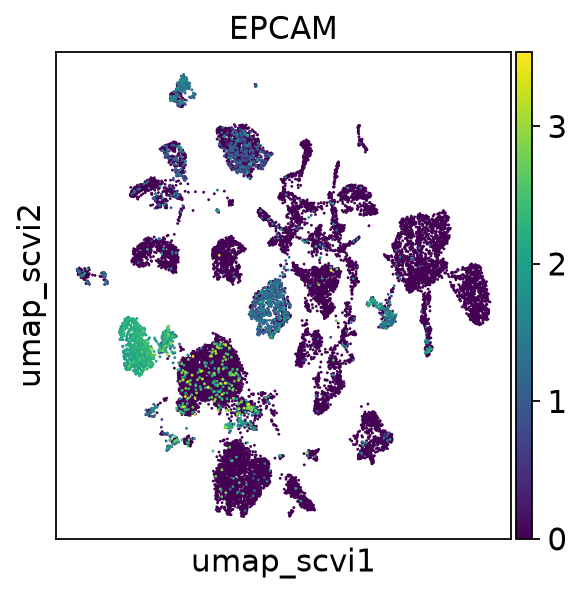

                  mean log-norm expr
T                              0.374
Epithelial/Tumor               0.331
DC                             0.149
NK                             0.052
Fibroblast                     0.037
Other                          0.025
B                              0.021
Macrophage                     0.017
Endothelial                    0.016
Monocyte                       0.000


In [12]:
TARGET = "EPCAM"   # starter default; change to ERBB2, ESR1, MKI67, PTPRC, CD68 or CD3D if you prefer
sc.pl.embedding(adata, basis="umap_scvi", color=TARGET, use_raw=True)
print(pd.DataFrame({"mean log-norm expr": [float(np.mean(adata.raw[adata.obs.cell_type_broad==c, TARGET].X.toarray())) for c in adata.obs.cell_type_broad.cat.categories]},
                   index=adata.obs.cell_type_broad.cat.categories).sort_values("mean log-norm expr", ascending=False).round(3))

**TODO (interpretation):** Which cell type(s) express your target? 

EPCAM has the highest mean expression in T cells (0.374) and in Epithelial/Tumor cells (0.331). It is detected in 26.7% of T cells and 21.7% of Epithelial/Tumor cells, and in T cells it ranges from about 5% in some donors to 71.5% in one donor (HTAPP-313). All 152 Epithelial/Tumor cells come from one donor. So in this sample I cannot say EPCAM marks only tumour cells. One possible reason is ambient RNA, but I did not test it.

---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [13]:
sc.settings.datasetdir = "data"
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/tmp/ipykernel_2834284/2633242922.py:2: FutureWarning: The function visium_sge is deprecated and will be removed in the future. Use :func:`squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)
spots x genes: (3798, 36601)


/scratch/bhatia.dh/conda/envs/biot8/lib/python3.12/site-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


## 2.2 · Pipeline and clustering  *(provided)*

In [14]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/tmp/ipykernel_2834284/4117200164.py:11: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

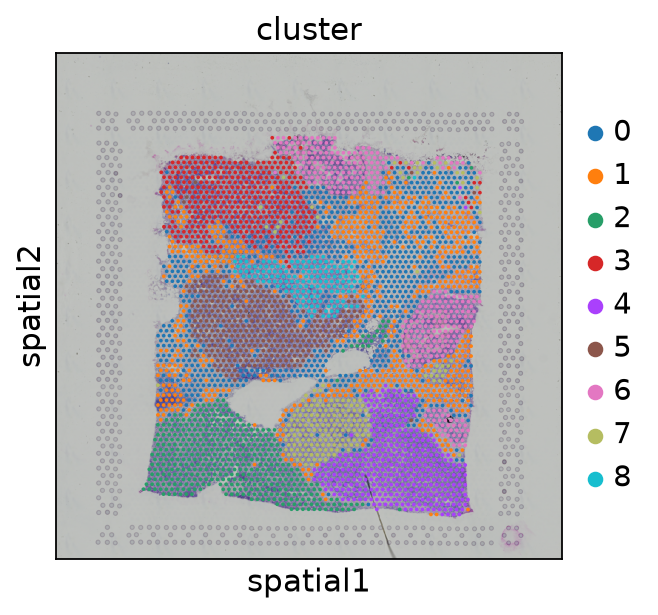

In [15]:
sq.pl.spatial_scatter(spatial, color="cluster")

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

The tissue splits into 9 domains, mostly in connected patches. Some follow visible regions of the H&E image. I did not name the domains as tumour, stroma or immune with marker genes, so I cannot say which is which.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [16]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_2834284/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


/tmp/ipykernel_2834284/4079614935.py:2: FutureWarning: Parameter `seed` of `spatial_autocorr()` is deprecated in favor of `rng` and will be removed in squidpy v1.9.0. It is now seeding a generator, i.e. `seed=0` is used as `numpy.random.default_rng(0)`, which may change the result.
  sq.gr.spatial_autocorr(spatial, mode="moran", genes=hv, n_perms=100, n_jobs=1, seed=0)


  0%|          | 0/100 [00:00<?, ?/s]

               I
MGP     0.868504
MALAT1  0.762550
CRISP3  0.726334
CPB1    0.711023
IGHG3   0.703817
IGLC2   0.700306
IGKC    0.680696
ALB     0.667866


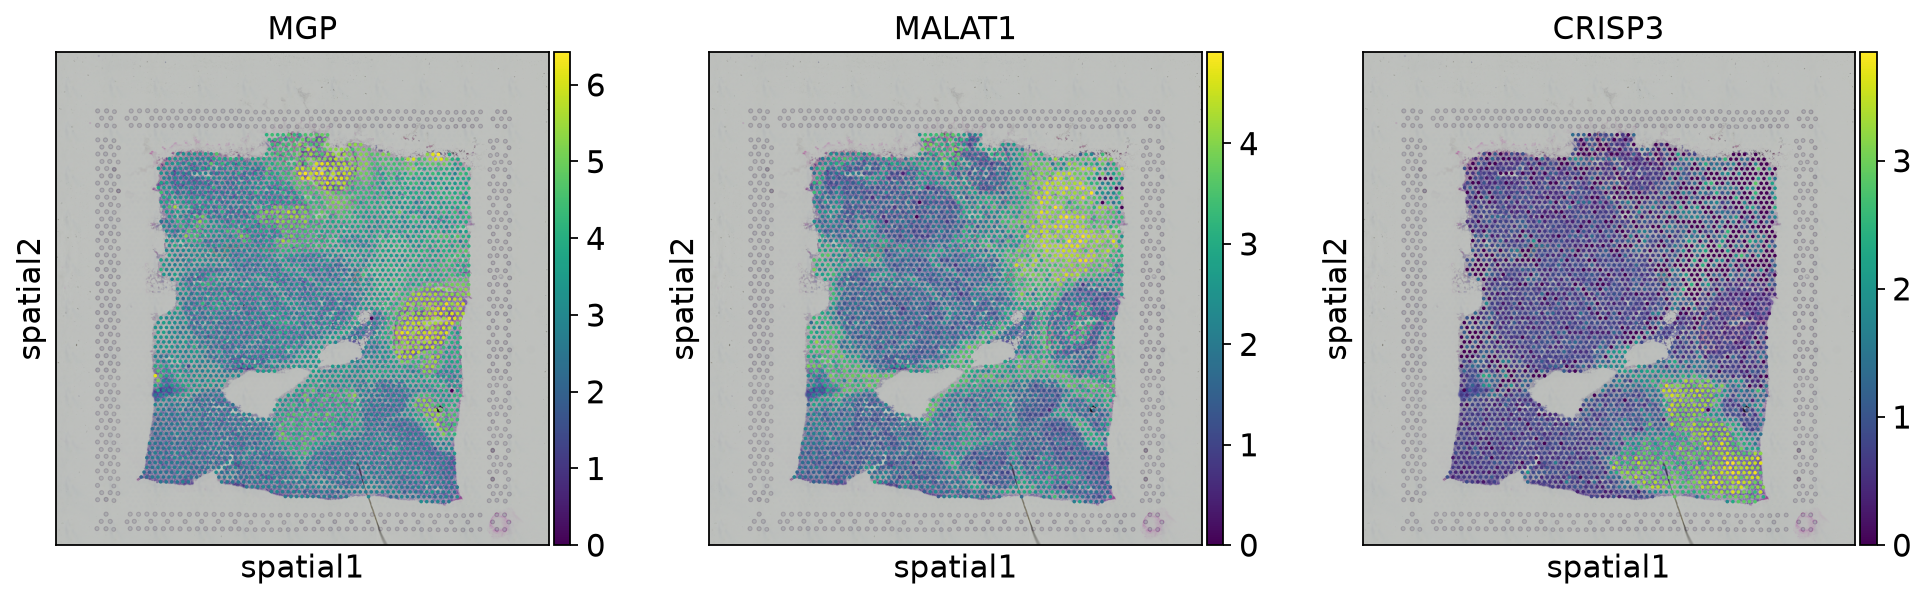

In [17]:
hv = spatial.var_names[spatial.var["highly_variable"]]
sq.gr.spatial_autocorr(spatial, mode="moran", genes=hv, n_perms=100, n_jobs=1, seed=0)
top = spatial.uns["moranI"].head(8); print(top[["I"]])
sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist())

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

nhood_enrichment:   0%|          | 0/1000 [00:00<?, ?perm/s]

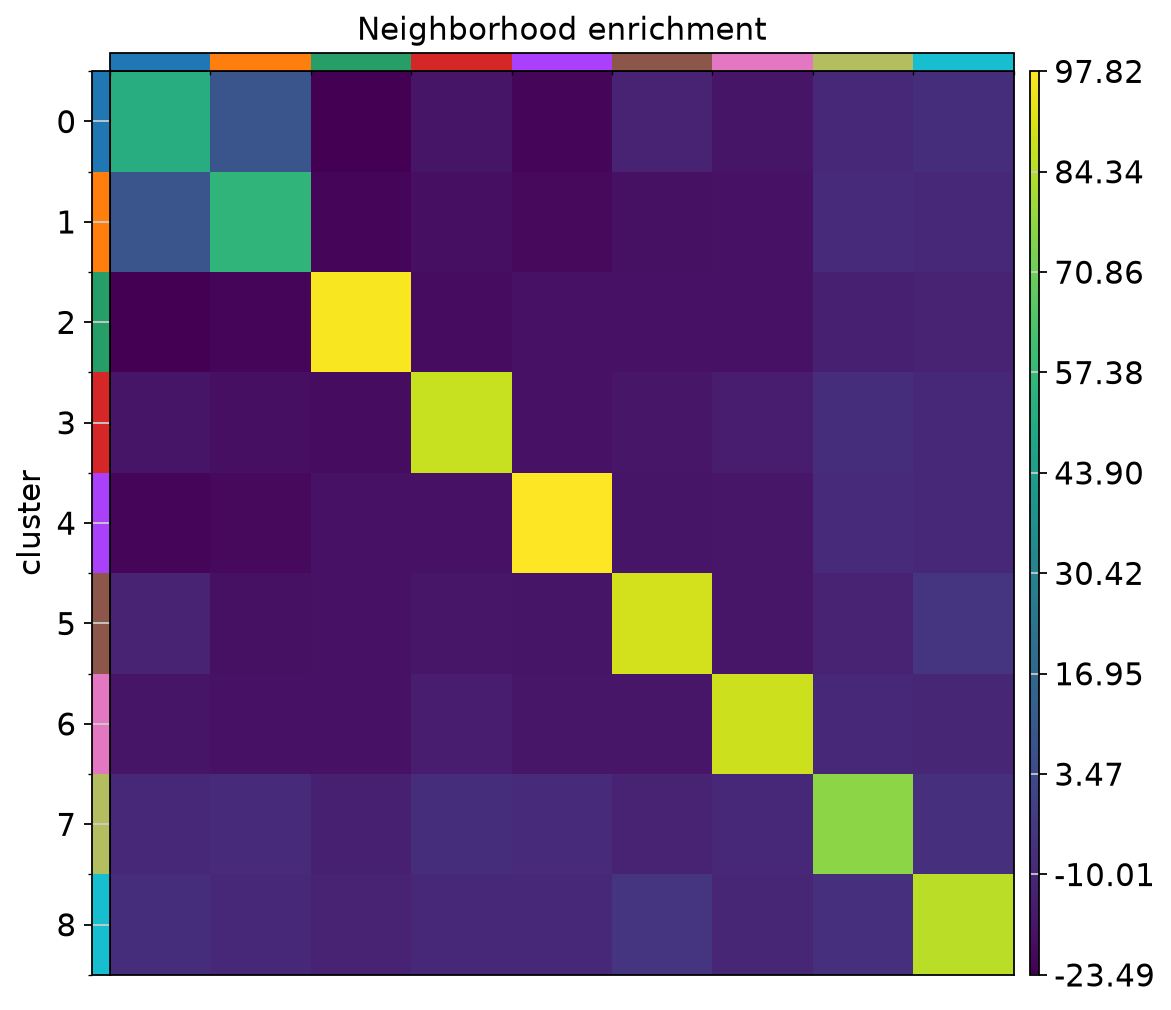

In [18]:
sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster")

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

Each domain sits next to itself (diagonal z-scores up to about 98). Off the diagonal the scores are near or below zero, except domains 0 and 1, which are modestly positive. I do not see a clear tumour-immune boundary, but I did not name the domains, so this is not a firm answer.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

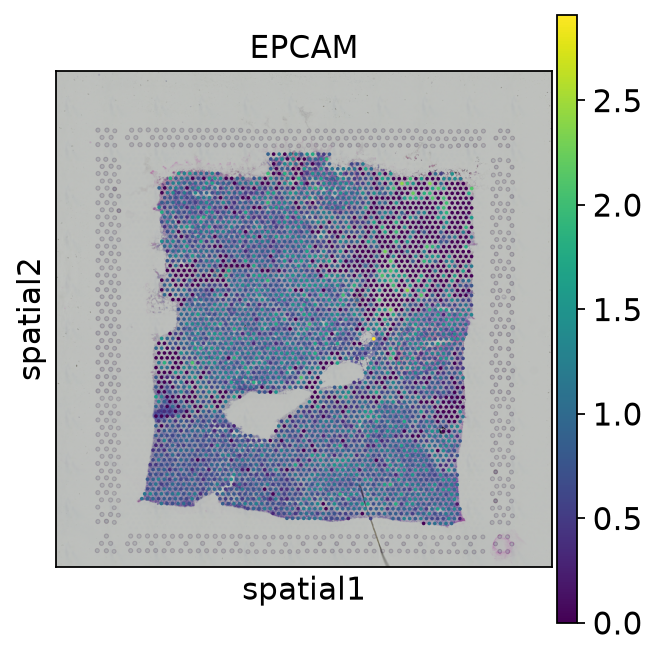

In [19]:
if TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(spatial, color=TARGET)
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")

**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

EPCAM is low and spread across the section, with a few higher spots toward the upper right. It does not sit in one domain, so I cannot place it in the tumour core, the invasive margin or an immune niche. This is one section from one patient.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.